# **<center>Car Price Prediction Project</center>**

#### Import Lib

In [1]:
import numpy as np
import pandas as pd

#### Ingest Data

In [2]:
data = 'https://raw.githubusercontent.com/alexeygrigorev/mlbookcamp-code/master/chapter-02-car-price/data.csv'
data

'https://raw.githubusercontent.com/alexeygrigorev/mlbookcamp-code/master/chapter-02-car-price/data.csv'

In [3]:
df=pd.read_csv(data)
df.head()

,Make,Model,Year,Engine Fuel Type,Engine HP,Engine Cylinders,Transmission Type,Driven_Wheels,Number of Doors,Market Category,Vehicle Size,Vehicle Style,highway MPG,city mpg,Popularity,MSRP
0,BMW,1 Series M,2011,premium unleaded (required),335.0,6.0,MANUAL,rear wheel drive,2.0,"Factory Tuner,Luxury,High-Performance",Compact,Coupe,26,19,3916,46135
1,BMW,1 Series,2011,premium unleaded (required),300.0,6.0,MANUAL,rear wheel drive,2.0,"Luxury,Performance",Compact,Convertible,28,19,3916,40650
2,BMW,1 Series,2011,premium unleaded (required),300.0,6.0,MANUAL,rear wheel drive,2.0,"Luxury,High-Performance",Compact,Coupe,28,20,3916,36350
3,BMW,1 Series,2011,premium unleaded (required),230.0,6.0,MANUAL,rear wheel drive,2.0,"Luxury,Performance",Compact,Coupe,28,18,3916,29450
4,BMW,1 Series,2011,premium unleaded (required),230.0,6.0,MANUAL,rear wheel drive,2.0,Luxury,Compact,Convertible,28,18,3916,34500


In [4]:
df.columns=df.columns.str.replace(' ','_').str.lower()

In [5]:
df.head()

,make,model,year,engine_fuel_type,engine_hp,engine_cylinders,transmission_type,driven_wheels,number_of_doors,market_category,vehicle_size,vehicle_style,highway_mpg,city_mpg,popularity,msrp
0,BMW,1 Series M,2011,premium unleaded (required),335.0,6.0,MANUAL,rear wheel drive,2.0,"Factory Tuner,Luxury,High-Performance",Compact,Coupe,26,19,3916,46135
1,BMW,1 Series,2011,premium unleaded (required),300.0,6.0,MANUAL,rear wheel drive,2.0,"Luxury,Performance",Compact,Convertible,28,19,3916,40650
2,BMW,1 Series,2011,premium unleaded (required),300.0,6.0,MANUAL,rear wheel drive,2.0,"Luxury,High-Performance",Compact,Coupe,28,20,3916,36350
3,BMW,1 Series,2011,premium unleaded (required),230.0,6.0,MANUAL,rear wheel drive,2.0,"Luxury,Performance",Compact,Coupe,28,18,3916,29450
4,BMW,1 Series,2011,premium unleaded (required),230.0,6.0,MANUAL,rear wheel drive,2.0,Luxury,Compact,Convertible,28,18,3916,34500


#### Normalizing the data

In [6]:
str_columns=df.dtypes[df.dtypes=='str'].index

In [7]:
str_columns

Index(['make', 'model', 'engine_fuel_type', 'transmission_type',
       'driven_wheels', 'market_category', 'vehicle_size', 'vehicle_style'],
      dtype='str')

In [8]:
for col in str_columns:
    df[col]=df[col].str.replace(' ','_').str.lower()

In [9]:
df

,make,model,year,engine_fuel_type,engine_hp,engine_cylinders,transmission_type,driven_wheels,number_of_doors,market_category,vehicle_size,vehicle_style,highway_mpg,city_mpg,popularity,msrp
0,bmw,1_series_m,2011,premium_unleaded_(required),335.0,6.0,manual,rear_wheel_drive,2.0,"factory_tuner,luxury,high-performance",compact,coupe,26,19,3916,46135
1,bmw,1_series,2011,premium_unleaded_(required),300.0,6.0,manual,rear_wheel_drive,2.0,"luxury,performance",compact,convertible,28,19,3916,40650
2,bmw,1_series,2011,premium_unleaded_(required),300.0,6.0,manual,rear_wheel_drive,2.0,"luxury,high-performance",compact,coupe,28,20,3916,36350
3,bmw,1_series,2011,premium_unleaded_(required),230.0,6.0,manual,rear_wheel_drive,2.0,"luxury,performance",compact,coupe,28,18,3916,29450
4,bmw,1_series,2011,premium_unleaded_(required),230.0,6.0,manual,rear_wheel_drive,2.0,luxury,compact,convertible,28,18,3916,34500
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
11909,acura,zdx,2012,premium_unleaded_(required),300.0,6.0,automatic,all_wheel_drive,4.0,"crossover,hatchback,luxury",midsize,4dr_hatchback,23,16,204,46120
11910,acura,zdx,2012,premium_unleaded_(required),300.0,6.0,automatic,all_wheel_drive,4.0,"crossover,hatchback,luxury",midsize,4dr_hatchback,23,16,204,56670
11911,acura,zdx,2012,premium_unleaded_(required),300.0,6.0,automatic,all_wheel_drive,4.0,"crossover,hatchback,luxury",midsize,4dr_hatchback,23,16,204,50620
11912,acura,zdx,2013,premium_unleaded_(recommended),300.0,6.0,automatic,all_wheel_drive,4.0,"crossover,hatchback,luxury",midsize,4dr_hatchback,23,16,204,50920


#### EDA

In [10]:
df.describe().round(2)

,year,engine_hp,engine_cylinders,number_of_doors,highway_mpg,city_mpg,popularity,msrp
count,11914.00,11845.00,11884.00,11908.00,11914.00,11914.00,11914.00,11914.00
mean,2010.38,249.39,5.63,3.44,26.64,19.73,1554.91,40594.74
std,7.58,109.19,1.78,0.88,8.86,8.99,1441.86,60109.10
min,1990.00,55.00,0.00,2.00,12.00,7.00,2.00,2000.00
25%,2007.00,170.00,4.00,2.00,22.00,16.00,549.00,21000.00
50%,2015.00,227.00,6.00,4.00,26.00,18.00,1385.00,29995.00
75%,2016.00,300.00,6.00,4.00,30.00,22.00,2009.00,42231.25
max,2017.00,1001.00,16.00,4.00,354.00,137.00,5657.00,2065902.00


In [11]:
df.isnull().sum()

make                    0
model                   0
year                    0
engine_fuel_type        3
engine_hp              69
engine_cylinders       30
transmission_type       0
driven_wheels           0
number_of_doors         6
market_category      3742
vehicle_size            0
vehicle_style           0
highway_mpg             0
city_mpg                0
popularity              0
msrp                    0
dtype: int64

##### Distribution of price

In [12]:
import matplotlib.pyplot as plt
import seaborn as sns 

%matplotlib inline

<Axes: xlabel='msrp', ylabel='Count'>

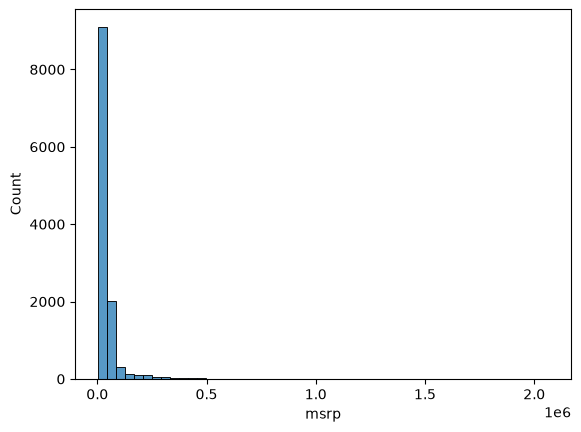

In [13]:
sns.histplot(df['msrp'], bins=50)

From the data we can see that it is long tail distribution. which means most of the data is on one side. if we look at the numbes most of the car price is in the range of 0 to 500K. and there are very few cars whose price is higher than that. The tail will confuse the algorithm thus we apply lograthmic distribution to the function. The result will be more compact. Fo large value the log values is not that big.

<Axes: xlabel='msrp', ylabel='Count'>

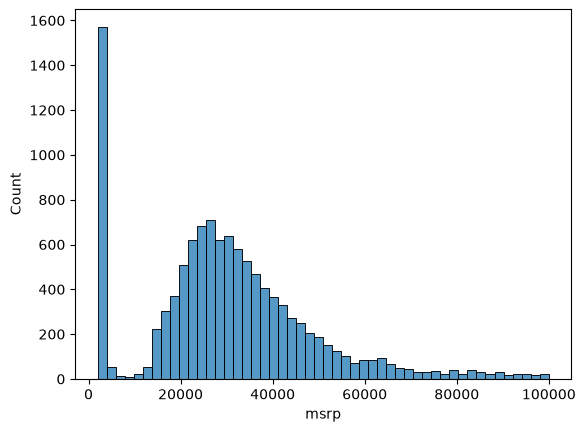

In [14]:
sns.histplot(df.msrp[df['msrp']<100000], bins=50)

In [15]:
np.log1p([1,10,100,1000])

array([0.69314718, 2.39789527, 4.61512052, 6.90875478])

In [16]:
price_logs=np.log1p(df.msrp)

In [17]:
price_logs.describe()

count    11914.000000
mean        10.113729
std          1.105703
min          7.601402
25%          9.952325
50%         10.308819
75%         10.650939
max         14.541078
Name: msrp, dtype: float64

<Axes: xlabel='msrp', ylabel='Count'>

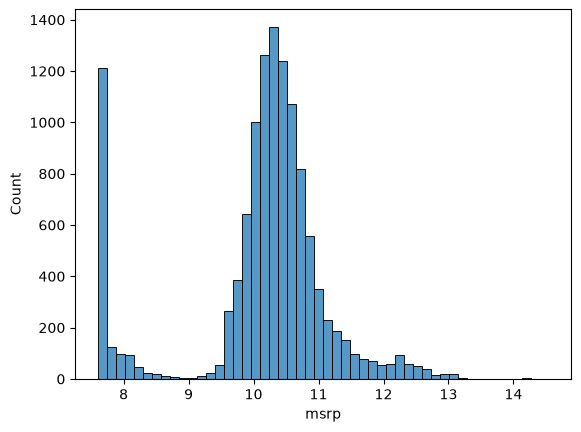

In [18]:
sns.histplot(price_logs, bins=50)

#### Setting up the validation framework

In [19]:
n=len(df)
n

11914

In [20]:
# Validation

n_val=int(n * 0.2)
n_test=int(n * 0.2)
n_train=n-n_val-n_test

In [21]:
n_train, n_test, n_val

(7150, 2382, 2382)

In [22]:
idx=np.arange(n)
np.random.seed(2)
np.random.shuffle(idx)
idx

array([2735, 6720, 5878, ..., 6637, 2575, 7336], shape=(11914,))

In [23]:
df_train=df.iloc[idx[:n_train]]
df_val=df.iloc[idx[n_train:n_train+n_val]]
df_test=df.iloc[idx[n_train+n_val:]]
len(df_train),len(df_val),len(df_test)

(7150, 2382, 2382)

In [24]:
df_train.head()

,make,model,year,engine_fuel_type,engine_hp,engine_cylinders,transmission_type,driven_wheels,number_of_doors,market_category,vehicle_size,vehicle_style,highway_mpg,city_mpg,popularity,msrp
2735,chevrolet,cobalt,2008,regular_unleaded,148.0,4.0,manual,front_wheel_drive,2.0,NaN,compact,coupe,33,24,1385,14410
6720,toyota,matrix,2012,regular_unleaded,132.0,4.0,automatic,front_wheel_drive,4.0,hatchback,compact,4dr_hatchback,32,25,2031,19685
5878,subaru,impreza,2016,regular_unleaded,148.0,4.0,automatic,all_wheel_drive,4.0,hatchback,compact,4dr_hatchback,37,28,640,19795
11190,volkswagen,vanagon,1991,regular_unleaded,90.0,4.0,manual,rear_wheel_drive,3.0,NaN,large,passenger_minivan,18,16,873,2000
4554,ford,f-150,2017,flex-fuel_(unleaded/e85),385.0,8.0,automatic,four_wheel_drive,4.0,flex_fuel,large,crew_cab_pickup,21,15,5657,56260


In [25]:
df_train=df_train.reset_index(drop=True)
df_val=df_val.reset_index(drop=True)
df_test=df_test.reset_index(drop=True)


In [26]:
y_train = np.log1p(df_train.msrp.values)
y_val = np.log1p(df_val.msrp.values)
y_test = np.log1p(df_test.msrp.values)

In [27]:
del df_train['msrp']
del df_val['msrp']
del df_test['msrp']

#### Linear Regression

Linear regression formula is **g(X) ≈ y**. Where g is our model, X is the feature matrix and y is our target - the price. The model g will be linear regression.

In [28]:
xi=[453,11,86] # Features of the car
w0= 7.17 # This will be the value of the car if we don't no anything about the car.
w=[0.01,0.04,0.002]  # respective weight of the features. Means how much importance each feature carries. 

In [29]:
def linear_reg(xi):
    
    n=len(xi)
    
    pred=w0
    
    for j in range(n):
        
        pred=pred+ w[j] * xi[j]
    
    return pred

In [30]:
linear_reg(xi) 

12.312

The output is w0+ w1*xi1 + w2*xi2 + w3*xi3 = y.  
7.17 + 0.01 * 453 + 0.04 * 11 +  0.002 * 86 = 12.312  
But this is not the price in dollars because we applied lograthmic earlier thus we need the exponent of the target variable to get the actual price. 

In [31]:
np.expm1(12.312)

np.float64(222347.2221101062)

In [32]:
def dot(xi, w):
    
    n= len(xi)
    res= 0.0 
    
    for j in range(n):
        
        res= res+ w[j] * xi[j]
    
    return res
    

In [33]:
def vector_linear_regression(xi):
    return w0+ dot(xi,w)

In [34]:
vector_linear_regression(xi)

12.312000000000001

#### Vector linear regression

In [35]:
X =np.array([[   1,  148,   24, 1385],
       [   1,  132,   25, 2031],
       [   1,  453,   11,   86]])
X

array([[   1,  148,   24, 1385],
       [   1,  132,   25, 2031],
       [   1,  453,   11,   86]])

In [36]:
w0 = 7.17
w = [0.01, 0.04, 0.002]
w_new = [w0] + w

In [37]:
def linear_regression(X):
    return X.dot(w_new)

In [38]:
linear_regression(X)

array([12.38 , 13.552, 12.312])

till now we were assinging the weights manually but how do we get those weights.

In [39]:
def train_linear_regression(X, y):
    ones = np.ones(X.shape[0])
    X = np.column_stack([ones, X])

    XTX = X.T.dot(X)
    XTX_inv = np.linalg.inv(XTX)
    w_full = XTX_inv.dot(X.T).dot(y)

    return w_full[0], w_full[1:] 

In [40]:
X = [
    [148, 24, 1385],
    [132, 25, 2031],
    [453, 11, 86],
    [158, 24, 185],
    [172, 25, 201],
    [413, 11, 86],
    [38,  54, 185],
    [142, 25, 431],
    [453, 31, 86],
]
X = np.array(X)

In [41]:
y = [100, 200, 150, 250, 100, 200, 150, 250, 120]

In [42]:
train_linear_regression(X, y)

(np.float64(300.06776692555627),
 array([-0.22774253, -2.5769413 , -0.02301206]))

These are the weights for feature 1,2,3. but we don't know the baseline model yet. 

In [43]:
ones = np.ones((X.shape[0],1))

In [44]:
result=np.column_stack((ones, X))

In [45]:
result

array([[1.000e+00, 1.480e+02, 2.400e+01, 1.385e+03],
       [1.000e+00, 1.320e+02, 2.500e+01, 2.031e+03],
       [1.000e+00, 4.530e+02, 1.100e+01, 8.600e+01],
       [1.000e+00, 1.580e+02, 2.400e+01, 1.850e+02],
       [1.000e+00, 1.720e+02, 2.500e+01, 2.010e+02],
       [1.000e+00, 4.130e+02, 1.100e+01, 8.600e+01],
       [1.000e+00, 3.800e+01, 5.400e+01, 1.850e+02],
       [1.000e+00, 1.420e+02, 2.500e+01, 4.310e+02],
       [1.000e+00, 4.530e+02, 3.100e+01, 8.600e+01]])

In [46]:
train_linear_regression(X, y)

(np.float64(300.06776692555627),
 array([-0.22774253, -2.5769413 , -0.02301206]))

#### Baseline model for prediction

In [47]:
df_train.dtypes

make                     str
model                    str
year                   int64
engine_fuel_type         str
engine_hp            float64
engine_cylinders     float64
transmission_type        str
driven_wheels            str
number_of_doors      float64
market_category          str
vehicle_size             str
vehicle_style            str
highway_mpg            int64
city_mpg               int64
popularity             int64
dtype: object

In [48]:
base = ['engine_hp', 'engine_cylinders', 'highway_mpg',
        'city_mpg', 'popularity']

In [49]:
df_train.isnull().sum()

make                    0
model                   0
year                    0
engine_fuel_type        1
engine_hp              40
engine_cylinders       14
transmission_type       0
driven_wheels           0
number_of_doors         6
market_category      2251
vehicle_size            0
vehicle_style           0
highway_mpg             0
city_mpg                0
popularity              0
dtype: int64

In [50]:
X_train = df_train[base].values

In [51]:
df_train[base].isnull().sum()

engine_hp           40
engine_cylinders    14
highway_mpg          0
city_mpg             0
popularity           0
dtype: int64

In [52]:
X_train = df_train[base].fillna(0).values

In [53]:
w0, w = train_linear_regression(X_train, y_train)

In [54]:
w0, w

(np.float64(7.927257388070037),
 array([ 9.70589522e-03, -1.59103494e-01,  1.43792133e-02,  1.49441072e-02,
        -9.06908672e-06]))

In [55]:
y_pred= w0+X_train.dot(w)

<Axes: ylabel='Count'>

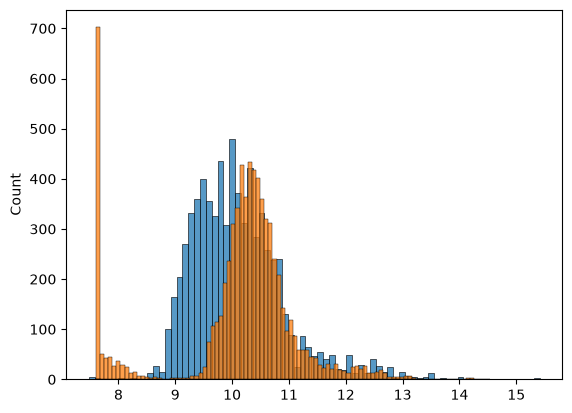

In [56]:
sns.histplot(y_pred)
sns.histplot(y_train)

#### RMSE

In [57]:
def rmse(y, y_pred):
    
    error= y-y_pred
    error= error ** 2
    mse=error.mean()
    
    return np.sqrt(mse)

In [65]:
rmse (y_train,y_pred)

np.float64(0.7554192603920132)

##### RMSE on validating data

In [59]:
def prepare_x(df):
    df.copy()
    df['age']= 2017-df['year']
    feature=base+['age']
    df_feature=df[feature]
    df_feature=df_feature.fillna(0)
    x= df_feature.values
    return x    

In [66]:
X_train=prepare_x(df_train)

In [69]:
w0,w=train_linear_regression(X_train,y_train)

In [70]:
w0,w

(np.float64(9.286850605506142),
 array([ 3.87296543e-03,  7.24889532e-02, -2.59712372e-03,  1.10445120e-02,
        -4.77015685e-05, -9.31651725e-02]))

In [71]:
x_val=prepare_x(df_val)

In [72]:
y_pred_val=w0 + x_val.dot(w)

In [73]:
rmse(y_val,y_pred_val)

np.float64(0.5172055461058327)

#### Categorical Variables

In [ ]:
list(df_train['engine_fuel_type'].value_counts().head(3).index)

['regular_unleaded',
 'premium_unleaded_(required)',
 'premium_unleaded_(recommended)']

In [96]:
df_train

,make,model,year,engine_fuel_type,engine_hp,engine_cylinders,transmission_type,driven_wheels,number_of_doors,market_category,vehicle_size,vehicle_style,highway_mpg,city_mpg,popularity,age
0,chevrolet,cobalt,2008,regular_unleaded,148.0,4.0,manual,front_wheel_drive,2.0,NaN,compact,coupe,33,24,1385,9
1,toyota,matrix,2012,regular_unleaded,132.0,4.0,automatic,front_wheel_drive,4.0,hatchback,compact,4dr_hatchback,32,25,2031,5
2,subaru,impreza,2016,regular_unleaded,148.0,4.0,automatic,all_wheel_drive,4.0,hatchback,compact,4dr_hatchback,37,28,640,1
3,volkswagen,vanagon,1991,regular_unleaded,90.0,4.0,manual,rear_wheel_drive,3.0,NaN,large,passenger_minivan,18,16,873,26
4,ford,f-150,2017,flex-fuel_(unleaded/e85),385.0,8.0,automatic,four_wheel_drive,4.0,flex_fuel,large,crew_cab_pickup,21,15,5657,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7145,bmw,4_series,2015,premium_unleaded_(required),300.0,6.0,automatic,rear_wheel_drive,2.0,"luxury,performance",midsize,convertible,31,20,3916,2
7146,volkswagen,beetle,2015,premium_unleaded_(recommended),210.0,4.0,automated_manual,front_wheel_drive,2.0,"hatchback,performance",compact,2dr_hatchback,30,24,873,2
7147,gmc,sierra_1500,2015,flex-fuel_(unleaded/e85),285.0,6.0,automatic,four_wheel_drive,4.0,flex_fuel,large,extended_cab_pickup,22,17,549,2
7148,rolls-royce,ghost,2014,premium_unleaded_(required),563.0,12.0,automatic,rear_wheel_drive,4.0,"exotic,luxury,performance",large,sedan,21,13,86,3


In [99]:
for v in [2,3,4]:
    df_train['no_of_doors_%s' % v]=(df_train.number_of_doors==v).astype('int')

In [106]:
del df_train['no_of_doors_2']
del df_train['no_of_doors_3']
del df_train['no_of_doors_4']

In [107]:
df_train

,make,model,year,engine_fuel_type,engine_hp,engine_cylinders,transmission_type,driven_wheels,number_of_doors,market_category,vehicle_size,vehicle_style,highway_mpg,city_mpg,popularity,age
0,chevrolet,cobalt,2008,regular_unleaded,148.0,4.0,manual,front_wheel_drive,2.0,NaN,compact,coupe,33,24,1385,9
1,toyota,matrix,2012,regular_unleaded,132.0,4.0,automatic,front_wheel_drive,4.0,hatchback,compact,4dr_hatchback,32,25,2031,5
2,subaru,impreza,2016,regular_unleaded,148.0,4.0,automatic,all_wheel_drive,4.0,hatchback,compact,4dr_hatchback,37,28,640,1
3,volkswagen,vanagon,1991,regular_unleaded,90.0,4.0,manual,rear_wheel_drive,3.0,NaN,large,passenger_minivan,18,16,873,26
4,ford,f-150,2017,flex-fuel_(unleaded/e85),385.0,8.0,automatic,four_wheel_drive,4.0,flex_fuel,large,crew_cab_pickup,21,15,5657,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7145,bmw,4_series,2015,premium_unleaded_(required),300.0,6.0,automatic,rear_wheel_drive,2.0,"luxury,performance",midsize,convertible,31,20,3916,2
7146,volkswagen,beetle,2015,premium_unleaded_(recommended),210.0,4.0,automated_manual,front_wheel_drive,2.0,"hatchback,performance",compact,2dr_hatchback,30,24,873,2
7147,gmc,sierra_1500,2015,flex-fuel_(unleaded/e85),285.0,6.0,automatic,four_wheel_drive,4.0,flex_fuel,large,extended_cab_pickup,22,17,549,2
7148,rolls-royce,ghost,2014,premium_unleaded_(required),563.0,12.0,automatic,rear_wheel_drive,4.0,"exotic,luxury,performance",large,sedan,21,13,86,3


In [113]:
def prepare_x_2(df):
    
    df=df.copy()
    features= base.copy()
    
    df['age']=2017-df.year
    features.append('age')
    
    for v in [2,3,4]:
        df['number_of_doors_%s' % v] =(df.number_of_doors==v).astype('int')
        features.append('number_of_doors_%s' % v)
    
    df_num= df[features]
    df_num=df_num.fillna(0)
    
    X=df_num.values
    
    return X

In [114]:
x_c=prepare_x_2(df_train)

In [115]:
x_c

array([[148.,   4.,  33., ...,   1.,   0.,   0.],
       [132.,   4.,  32., ...,   0.,   0.,   1.],
       [148.,   4.,  37., ...,   0.,   0.,   1.],
       ...,
       [285.,   6.,  22., ...,   0.,   0.,   1.],
       [563.,  12.,  21., ...,   0.,   0.,   1.],
       [200.,   4.,  31., ...,   0.,   0.,   1.]], shape=(7150, 9))

In [118]:
df_train.dtypes

make                     str
model                    str
year                   int64
engine_fuel_type         str
engine_hp            float64
engine_cylinders     float64
transmission_type        str
driven_wheels            str
number_of_doors      float64
market_category          str
vehicle_size             str
vehicle_style            str
highway_mpg            int64
city_mpg               int64
popularity             int64
age                    int64
dtype: object

In [127]:
cat_df=['transmission_type','driven_wheels','vehicle_size']

In [128]:
catogories={}
for v in cat_df:
    catogories[v]=list(df[v].value_counts().index)
    

In [129]:
catogories

{'transmission_type': ['automatic',
  'manual',
  'automated_manual',
  'direct_drive',
  'unknown'],
 'driven_wheels': ['front_wheel_drive',
  'rear_wheel_drive',
  'all_wheel_drive',
  'four_wheel_drive'],
 'vehicle_size': ['compact', 'midsize', 'large']}

In [135]:
for key,value in catogories.items():
    for v in value:
        df[key + '_%s' % v]=((df[key])==v).astype('int')

transmission_type_automatic
transmission_type_manual
transmission_type_automated_manual
transmission_type_direct_drive
transmission_type_unknown
driven_wheels_front_wheel_drive
driven_wheels_rear_wheel_drive
driven_wheels_all_wheel_drive
driven_wheels_four_wheel_drive
vehicle_size_compact
vehicle_size_midsize
vehicle_size_large


In [145]:
def prepare_x_3(df):
    
    df=df.copy()
    features= base.copy()
    
    df['age']=2017-df.year
    features.append('age')
    
    for key,value in catogories.items():
        
        for v in value:
            
            df['%s_%s' % (key,v)]=(df[key]==v).astype('int')
            features.append('%s_%s' % (key,v))
    
    df_num= df[features]
    df_num=df_num.fillna(0)
    
    X=df_num.values
    return X
    

In [146]:
x_c_final=prepare_x_3(df_train)

In [147]:
x_c_final

array([[148.,   4.,  33., ...,   1.,   0.,   0.],
       [132.,   4.,  32., ...,   1.,   0.,   0.],
       [148.,   4.,  37., ...,   1.,   0.,   0.],
       ...,
       [285.,   6.,  22., ...,   0.,   0.,   1.],
       [563.,  12.,  21., ...,   0.,   0.,   1.],
       [200.,   4.,  31., ...,   0.,   1.,   0.]], shape=(7150, 18))

In [149]:
w0, w= train_linear_regression_regularized(x_c_final,y_train,r=0.01)

In [152]:
y_pred_c_final= w0 + x_c_final.dot(w)

In [153]:
rmse(y_train,y_pred_c_final)

np.float64(0.49858154765485513)

Regularization

In [148]:
def train_linear_regression_regularized(X, y, r):
    
    ones=np.ones(X.shape[0])
    X=np.column_stack([ones,X])
    
    XTX= X.T.dot(X)
    XTX= XTX + r * np.eye(XTX.shape[0])
    
    XTX_inv= np.linalg.inv(XTX)
    w_full= XTX_inv.dot(X.T).dot(y)
    
    return w_full[0],w_full[1:]

In [85]:
X_train=prepare_x(df_train)

w0,w=train_linear_regression_regularized(X_train,y_train, r=0.01)

y_pred= w0 + X_train.dot(w)

rmse(y_train, y_pred)

np.float64(0.5175055554223711)

In [86]:
x_val=prepare_x(df_val)
y_pred= w0 + x_val.dot(w)

rmse(y_val, y_pred)

np.float64(0.5172084604134598)

Tuning the model

In [156]:

for r in [0.0, 0.00001, 0.001, 0.01, 0.1, 10]:
    
    X_train=prepare_x_3(df_train)

    w0,w=train_linear_regression_regularized(X_train,y_train, r)
    
    x_val=prepare_x_3(df_val)
    y_pred= w0 + x_val.dot(w)

    print(rmse(y_val, y_pred))
    
    
    

142.19765990615107
0.49948081448199844
0.49948078299352866
0.4994803356366062
0.49947836749830393
0.5090013712952016


In [157]:
min(142.19765990615107,
0.49948081448199844,
0.49948078299352866,
0.4994803356366062,
0.49947836749830393,
0.5090013712952016)

0.49947836749830393

Using the model

In [158]:
df_full_train= pd.concat([df_train, df_val])
df_full_train = df_full_train.reset_index(drop=True)

X=prepare_x_3(df_full_train)
    
y_full_train = np.concatenate([y_train, y_val])

w0,w=train_linear_regression_regularized(X,y_full_train, r=0.1)

    
x_test=prepare_x_3(df_test)
y_pred= w0 + x_test.dot(w)

rmse(y_test, y_pred)

np.float64(0.4951393492206288)

In [162]:
new_car=df_test.iloc[20].to_dict()
predict_car=pd.DataFrame([new_car])

In [163]:
predict_car

,make,model,year,engine_fuel_type,engine_hp,engine_cylinders,transmission_type,driven_wheels,number_of_doors,market_category,vehicle_size,vehicle_style,highway_mpg,city_mpg,popularity
0,toyota,sienna,2015,regular_unleaded,266.0,6.0,automatic,front_wheel_drive,4.0,NaN,large,passenger_minivan,25,18,2031


In [164]:
x_small=prepare_x_3(predict_car)

In [167]:
y_pred= w0 + x_small.dot(w)

In [173]:
y_pred

array([10.51441786])

In [172]:
np.expm1(y_pred)

array([36841.88716725])

In [171]:
np.expm1(y_test[20])

np.float64(35000.00000000001)